In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm

In [2]:
df = pd.read_csv('50_Startups.csv')
df.head()

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing Spend  50 non-null     float64
 3   State            50 non-null     object 
 4   Profit           50 non-null     float64
dtypes: float64(4), object(1)
memory usage: 2.1+ KB


In [4]:
# --- Separar en X (independientes) e y (dependiente) ---
# Aquí los datos siguen teniendo nombres legibles en Pandas
X = df.drop(columns=['Profit'])
y = df['Profit']


In [5]:
# --- Convertir a Dummies por nombre de columna ---
# Convertimos 'State' a dummies, Drop first true nos ayuda a evitar la trampa de las dummies
X = pd.get_dummies(X, columns=['State'], dtype=int, drop_first=True)
X.head()

,R&D Spend,Administration,Marketing Spend,State_Florida,State_New York
0,165349.20,136897.80,471784.10,0,1
1,162597.70,151377.59,443898.53,0,0
2,153441.51,101145.55,407934.54,1,0
3,144372.41,118671.85,383199.62,0,1
4,142107.34,91391.77,366168.42,1,0


In [6]:
# --- División en Entrenamiento y Prueba ---
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [7]:
#Entrenar el modelo de regresión líneal
regressor = LinearRegression()
regressor.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [8]:
#Predicción del test
y_pred = regressor.predict(X_test)
print('------Valores predichos-----')
print(y_pred)
print('------Valores reales-----')
print(y_test)

------Valores predichos-----
[114664.4171587   90593.15531618  75692.84151576  70221.88679649
 179790.2551487  171576.9201852   49753.58752024 102276.65888937
  58649.37795765  98272.02561132]
------Valores reales-----
27    105008.31
35     96479.51
40     78239.91
38     81229.06
2     191050.39
3     182901.99
48     35673.41
29    101004.64
46     49490.75
31     97483.56
Name: Profit, dtype: float64


In [9]:
# 1. Obtener el porcentaje de efectividad en el conjunto de ENTRENAMIENTO
efectividad_train = regressor.score(X_train, y_train)
print(f"Porcentaje de efectividad (Entrenamiento): {efectividad_train * 100:.2f}%")

# 2. El porcentaje REALMENTE importante (en el conjunto de PRUEBA o TEST)
efectividad_test = regressor.score(X_test, y_test)
print(f"Porcentaje de efectividad (Prueba): {efectividad_test * 100:.2f}%")

Porcentaje de efectividad (Entrenamiento): 94.24%
Porcentaje de efectividad (Prueba): 96.50%


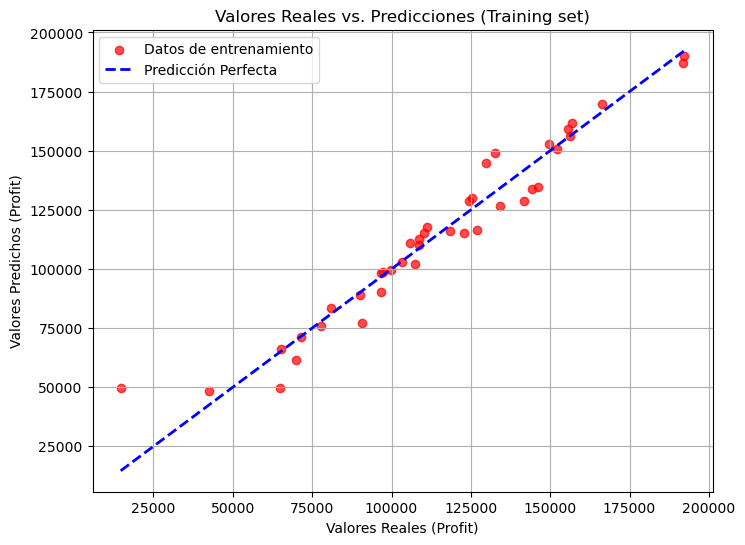

In [10]:
# 1. Generamos las predicciones del modelo para el conjunto de entrenamiento
y_pred_train = regressor.predict(X_train)

# 2. Graficamos Real vs Predicho
plt.figure(figsize=(8, 6))
plt.scatter(y_train, y_pred_train, color='red', alpha=0.7, label='Datos de entrenamiento')

# Linea de referencia ideal (Donde Real = Predicho)
lims = [min(min(y_train), min(y_pred_train)), max(max(y_train), max(y_pred_train))]
plt.plot(lims, lims, color='blue', linestyle='--', linewidth=2, label='Predicción Perfecta')

plt.title('Valores Reales vs. Predicciones (Training set)')
plt.xlabel('Valores Reales (Profit)')
plt.ylabel('Valores Predichos (Profit)')
plt.legend()
plt.grid(True)
plt.show()

### Eliminación hacia atrás (Modelo optimo RLM)

In [11]:

# Inserta una columna llamada 'const' llena de 1s en la posición 0 (al inicio)
# Se adapta automáticamente al tamaño real de X
X.insert(0, 'const', 1)
X.head()


,const,R&D Spend,Administration,Marketing Spend,State_Florida,State_New York
0,1,165349.20,136897.80,471784.10,0,1
1,1,162597.70,151377.59,443898.53,0,0
2,1,153441.51,101145.55,407934.54,1,0
3,1,144372.41,118671.85,383199.62,0,1
4,1,142107.34,91391.77,366168.42,1,0


In [13]:
SL=0.05

def backwardEliminationPandas(X_df, y_series, SL):
    """
    Realiza la eliminación hacia atrás en un DataFrame de Pandas
    basándose en el nivel de significancia (sl).
    """
    # Creamos una copia para no modificar el DataFrame original X
    X_opt = X_df.copy()
    
    while True:
        # 1. Ajustar el modelo OLS con las columnas actuales de X_opt
        model = sm.OLS(endog=y_series, exog=X_opt).fit()
        
        # 2. Obtener el p-valor más alto y el nombre de su variable
        # Excluimos 'const' de la eliminación para que siempre se quede en el modelo
        p_values = model.pvalues.drop('const', errors='ignore')
        
        max_p_value = p_values.max()
        max_p_variable = p_values.idxmax()
        
        # 3. Si el p-valor máximo supera el umbral, eliminamos la variable
        if max_p_value > SL:
            print(f"Eliminando columna: '{max_p_variable}' (P-valor: {max_p_value:.4f})")
            X_opt = X_opt.drop(columns=[max_p_variable])
        else:
            # Si ningún p-valor supera el SL, el modelo está optimizado
            break
            
    # Mostramos el resumen final del modelo optimizado
    print("\n" + "="*50)
    print("¡ELIMINACIÓN HACIA ATRÁS COMPLETADA!")
    print("="*50)
    print(model.summary())
    
    return X_opt

# --- Cómo usar la función --- #
# Guardamos en X_final únicamente las columnas óptimas

X_final = backwardEliminationPandas(X, y, SL)


Eliminando columna: 'State_New York' (P-valor: 0.9898)
Eliminando columna: 'State_Florida' (P-valor: 0.9398)
Eliminando columna: 'Administration' (P-valor: 0.6018)
Eliminando columna: 'Marketing Spend' (P-valor: 0.0600)

¡ELIMINACIÓN HACIA ATRÁS COMPLETADA!
                            OLS Regression Results                            
Dep. Variable:                 Profit   R-squared:                       0.947
Model:                            OLS   Adj. R-squared:                  0.945
Method:                 Least Squares   F-statistic:                     849.8
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           3.50e-32
Time:                        04:10:26   Log-Likelihood:                -527.44
No. Observations:                  50   AIC:                             1059.
Df Residuals:                      48   BIC:                             1063.
Df Model:                           1                                         
Covariance Type:            non

#creamos un df que al final solo va a contener las variables optimas para el modelo
# 1. Definimos el nivel de significancia
SL = 0.05

# 2. Creamos X_opt seleccionando todas las columnas por su nombre
# Al principio incluimos absolutamente todas las variables
X_opt = X[['const', 'R&D Spend', 'Administration', 'Marketing Spend', 'State_Florida', 'State_New York']]

# 3. Ajustamos el modelo OLS
# Nota: Usamos sm.OLS directamente (en lugar de statsmodels.formula.api)
regression_OLS = sm.OLS(endog=y, exog=X_opt).fit()

# 4. Mostramos el resumen
print(regression_OLS.summary())